## Sampling and Sampling Distributions

### Learning Goals
* Distinguish a dataset's population distribution from the sampling distribution of a statistic.
* Explore random sampling mechanics and the behavior of sample means.
* Understand how sample size affects the precision and variability of statistical estimates.

---

### 1. Population and Repeated Samples

In statistics, we rarely observe the entire population. Instead, we draw samples to estimate population parameters. A **sampling distribution** describes how a sample statistic (like the sample mean) varies across many different random samples drawn from the same population.

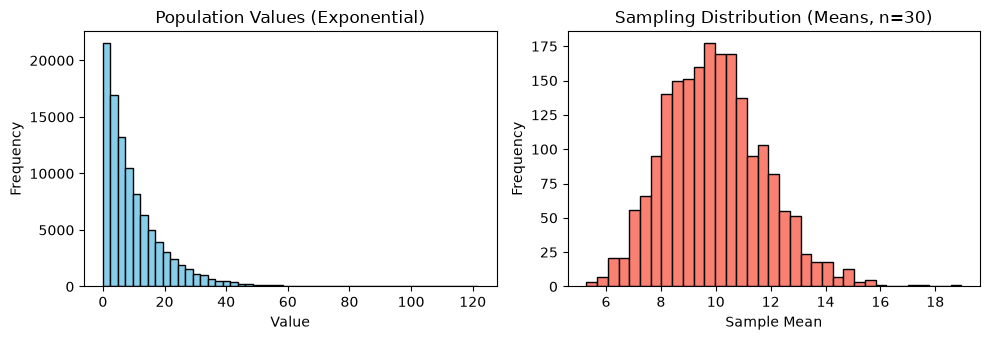

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
population = rng.exponential(scale=10, size=100_000)

# Simulate repeated sampling (2000 samples of size 30)
sample_means = [rng.choice(population, size=30, replace=True).mean() for _ in range(2000)]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

axes[0].hist(population, bins=50, color='skyblue', edgecolor='black')
axes[0].set_title("Population Values (Exponential)")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Frequency")

axes[1].hist(sample_means, bins=35, color='salmon', edgecolor='black')
axes[1].set_title("Sampling Distribution (Means, n=30)")
axes[1].set_xlabel("Sample Mean")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 2. What Varies?

* **Individual Observations vs. Statistics:** A single data point changes from observation to observation. A sample statistic (such as $\bar{x}$) changes *from sample to sample*.
* **The Sampling Distribution:** This distribution captures the variability of the statistic itself, forming the theoretical bedrock for confidence intervals and hypothesis testing.

---

### 3. Sample Size and Precision

As sample size ($n$) increases, the variability of the sample mean decreases. This dispersion of the sample mean is known as the **standard error** ($SE$).

In [2]:
rng = np.random.default_rng(7)

print("Standard error across different sample sizes (n):")
for n in [5, 30, 100]:
    means = [rng.choice(population, size=n, replace=True).mean() for _ in range(1500)]
    se = np.std(means, ddof=1)
    print(f"  n = {n:3d}  |  SD of sample means (SE) = {se:.3f}")

Standard error across different sample sizes (n):
  n =   5  |  SD of sample means (SE) = 4.444
  n =  30  |  SD of sample means (SE) = 1.826
  n = 100  |  SD of sample means (SE) = 1.010


### Interpretation

> **The Square Root Law:** Larger samples reduce the sampling variability (standard error) of a mean roughly in proportion to:
> $$
> SE \propto \frac{1}{\sqrt{n}}
> $$
> This holds true provided observations are independent and the population has a finite variance. Doubling sample size does not halve the error; you must quadruple it to cut the error in half.

---

### Exercises

Try each problem before running the verification code below:

1. Explain the difference between a population histogram and a sampling distribution.
2. Predict what happens to the standard error of the mean when the sample size quadruples (multiplies by 4).
3. Name two ways a sample can become unrepresentative of its target population.

In [3]:
# --- Exercise Verification & Demonstration ---
print("=== Exercise Explanations & Quick Checks ===")

print("\n1. Population Histogram vs. Sampling Distribution:")
print("   - Population Histogram: Shows the frequency of individual raw values in the entire population.")
print("   - Sampling Distribution: Shows the frequency of aggregated statistics (like means) across many samples.")

print("\n2. Impact of Quadrupling Sample Size:")
print("   - Since SE scales with 1 / sqrt(n), quadrupling n (multiplying by 4) results in sqrt(4) = 2,")
print("     meaning the standard error is cut exactly in half.")

print("\n3. Sources of Unrepresentative Samples (Sampling Bias):")
print("   - Selection Bias: Certain members of the population are systematically more likely to be chosen.")
print("   - Non-Response Bias: Individuals who choose to participate differ systematically from those who do not.")

=== Exercise Explanations & Quick Checks ===

1. Population Histogram vs. Sampling Distribution:
   - Population Histogram: Shows the frequency of individual raw values in the entire population.
   - Sampling Distribution: Shows the frequency of aggregated statistics (like means) across many samples.

2. Impact of Quadrupling Sample Size:
   - Since SE scales with 1 / sqrt(n), quadrupling n (multiplying by 4) results in sqrt(4) = 2,
     meaning the standard error is cut exactly in half.

3. Sources of Unrepresentative Samples (Sampling Bias):
   - Selection Bias: Certain members of the population are systematically more likely to be chosen.
   - Non-Response Bias: Individuals who choose to participate differ systematically from those who do not.
